# Visible ships — final results and visualisations


In [1]:
from pathlib import Path
from google.colab import drive
import json, os, sys, subprocess, zipfile
drive.mount('/content/drive')
DRIVE = Path('/content/drive/MyDrive')
ROOT = DRIVE / 'Visible_Ship_Study'
package = DRIVE / 'Visible_Ship_Study_Package.zip'
assert package.is_file(), f'Upload {package.name} to MyDrive'
with zipfile.ZipFile(package) as archive:
    assert archive.testzip() is None, 'Package ZIP is damaged'
    archive.extractall(DRIVE)
required = ['pyproject.toml', 'environments/modern.txt', 'environments/mmdetection.txt',
            'scripts/setup_environment.py', 'sarstudy/visible.py', 'configs/visible.json']
for name in required:
    assert (ROOT / name).is_file(), f'Package file missing: {name}'
manifest = ROOT / 'data/visible/manifest.json'
if not manifest.is_file():
    dataset_zip = DRIVE / 'Visible_Ship_Dataset.zip'
    assert dataset_zip.is_file(), f'Upload {dataset_zip.name} to MyDrive'
    with zipfile.ZipFile(dataset_zip) as archive:
        assert archive.testzip() is None, 'Dataset ZIP is damaged'
        archive.extractall(DRIVE)
dataset = json.loads(manifest.read_text())
assert dataset['seed'] == 42
assert dataset['counts'] == {'train': 1000, 'val': 250, 'test': 500}
print('Dataset:', dataset['counts'])
print('Project:', ROOT)


Mounted at /content/drive
Dataset: {'train': 1000, 'val': 250, 'test': 500}
Project: /content/drive/MyDrive/Visible_Ship_Study


In [2]:
%pip -q install numpy pandas matplotlib Pillow pycocotools
sys.path.insert(0, str(ROOT))
from sarstudy.config import StudyConfig
from sarstudy.reports import aggregate
settings = json.loads((ROOT / 'configs/visible.json').read_text())
results = aggregate(StudyConfig(**settings))
display(results)


Missing: [{'dataset': 'visible', 'model': 'samsar', 'split': 'test'}]
Reports: /content/drive/MyDrive/Visible_Ship_Study/reports/visible_v1_seed42


,model,training_dataset,experiment,clearml_task_id,split_fingerprint,checkpoint_sha256,protocol,params_M,gpu,fps_protocol,...,AP,mAP,num_detections,Precision,Recall,F1,confidence_threshold,dataset,FPS,source_file
0,yolo26n_seg,visible,visible_v1_seed42,9645b70cae8c480f859ff3e15c4737f2,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,d668ac790eb011d053e17cd645d2e9f502a462432bd827...,end2end,3.053055,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,53.480383,53.480383,13225,81.493506,66.226913,73.071325,0.246224,visible,17.042082,/content/drive/MyDrive/Visible_Ship_Study/runs...
1,yolo26s_seg,visible,visible_v1_seed42,d3754aaea316412c8f006b5f30a7befa,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,9152aa64ce2714dcfa2e8825ad00eea413191b3ab77e69...,end2end,11.434463,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,56.971643,56.971643,8631,79.656160,73.350923,76.373626,0.173005,visible,22.801024,/content/drive/MyDrive/Visible_Ship_Study/runs...
2,yolo26m_seg,visible,visible_v1_seed42,5277535a16f4410cb269e61eda6ab7d3,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,dca2be478f78070b6ea1c33211e6dd6733e29e6d4158f8...,end2end,26.969951,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,58.350277,58.350277,5275,76.883117,78.100264,77.486911,0.098855,visible,25.019622,/content/drive/MyDrive/Visible_Ship_Study/runs...
3,rfdetr_seg,visible,visible_v1_seed42,1db2a0a96eac42f2bb416d18cd5d1a30,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,f079cfad903c25a28b9ca5c941ee341de523a9574ffc8e...,end2end,33.675045,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,70.755088,70.755088,40374,93.956835,86.147757,89.883001,0.403432,visible,7.643581,/content/drive/MyDrive/Visible_Ship_Study/runs...
4,ship_contour,visible,visible_v1_seed42,e2144d2cd00c41dab5bdbb576a713e87,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,402106000fa478e65d45dd3065060718f224197ff7c6a5...,end2end,22.009385,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,0.000031,0.000031,49999,0.000000,0.000000,0.000000,0.067069,visible,4.602453,/content/drive/MyDrive/Visible_Ship_Study/runs...
5,swininsseg,visible,visible_v1_seed42,1cca2000654445c4950aa2e45f7b58c6,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,1cbc1ce826490b2fed435330e34f867389589576721823...,end2end,73.100763,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,46.384311,46.384311,4957,86.736475,65.567282,74.680691,0.466028,visible,14.938031,/content/drive/MyDrive/Visible_Ship_Study/runs...
6,solov2_gala,visible,visible_v1_seed42,92235a32c02f49988629678cc3581d13,a4c149a58f0800ab531ac66435101584874a6f2de2911e...,df110eebc44ade36b0f2dcf023146627eb536f01a2f66c...,end2end,46.929041,NVIDIA A100-SXM4-40GB,batch1_local_image_to_original_mask_rle_framew...,...,30.076540,30.076540,4427,85.146444,53.693931,65.857605,0.688892,visible,21.948749,/content/drive/MyDrive/Visible_Ship_Study/runs...


## Saved training and validation curves


yolo26n_seg


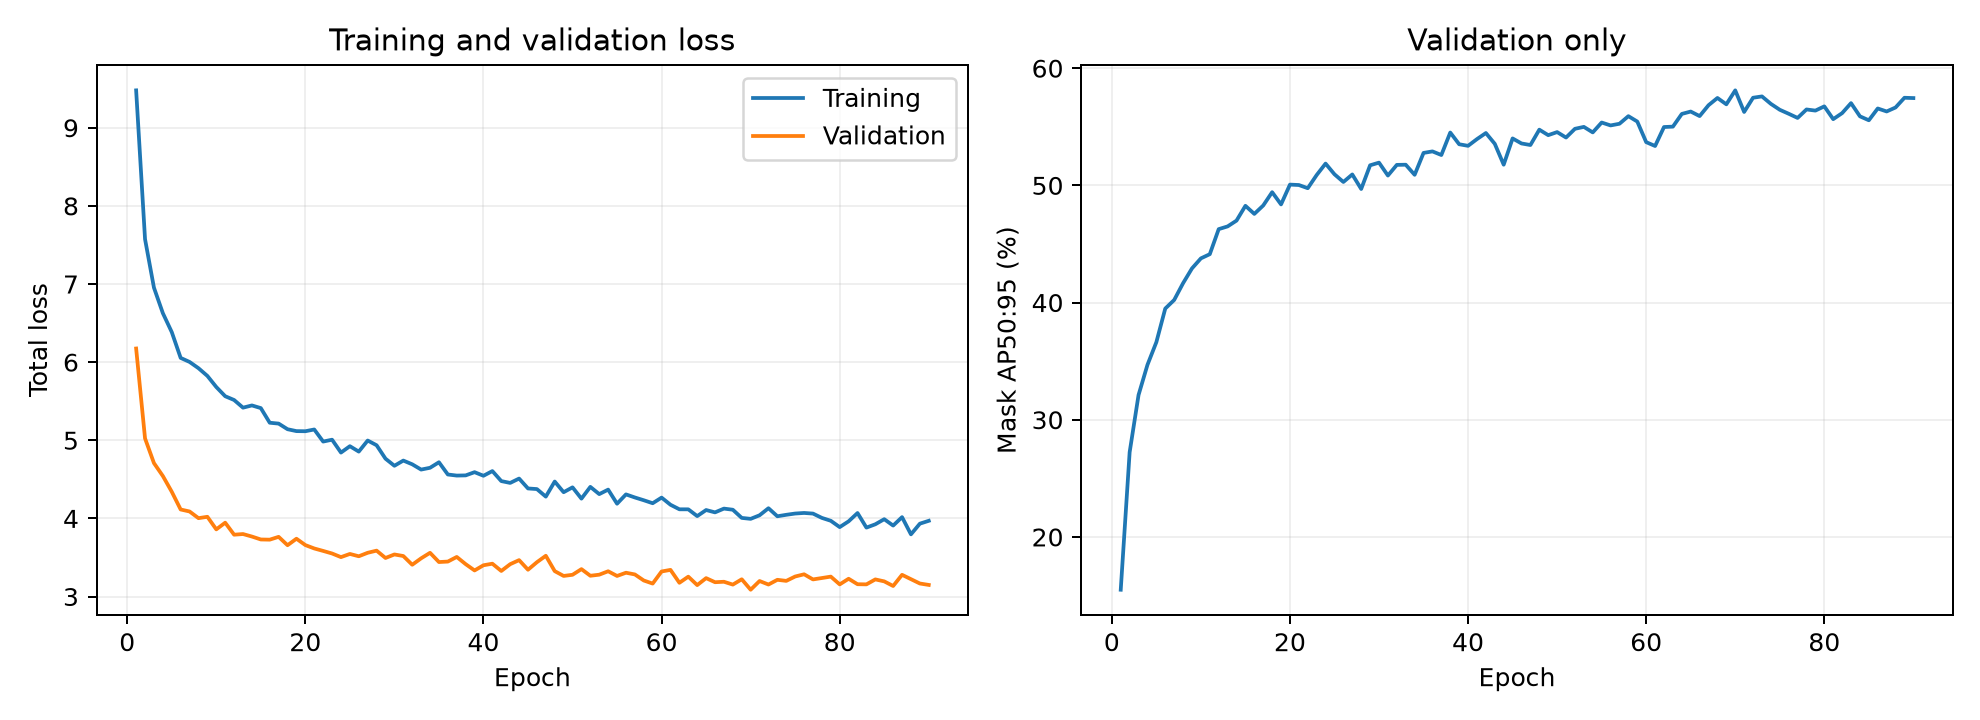

yolo26s_seg


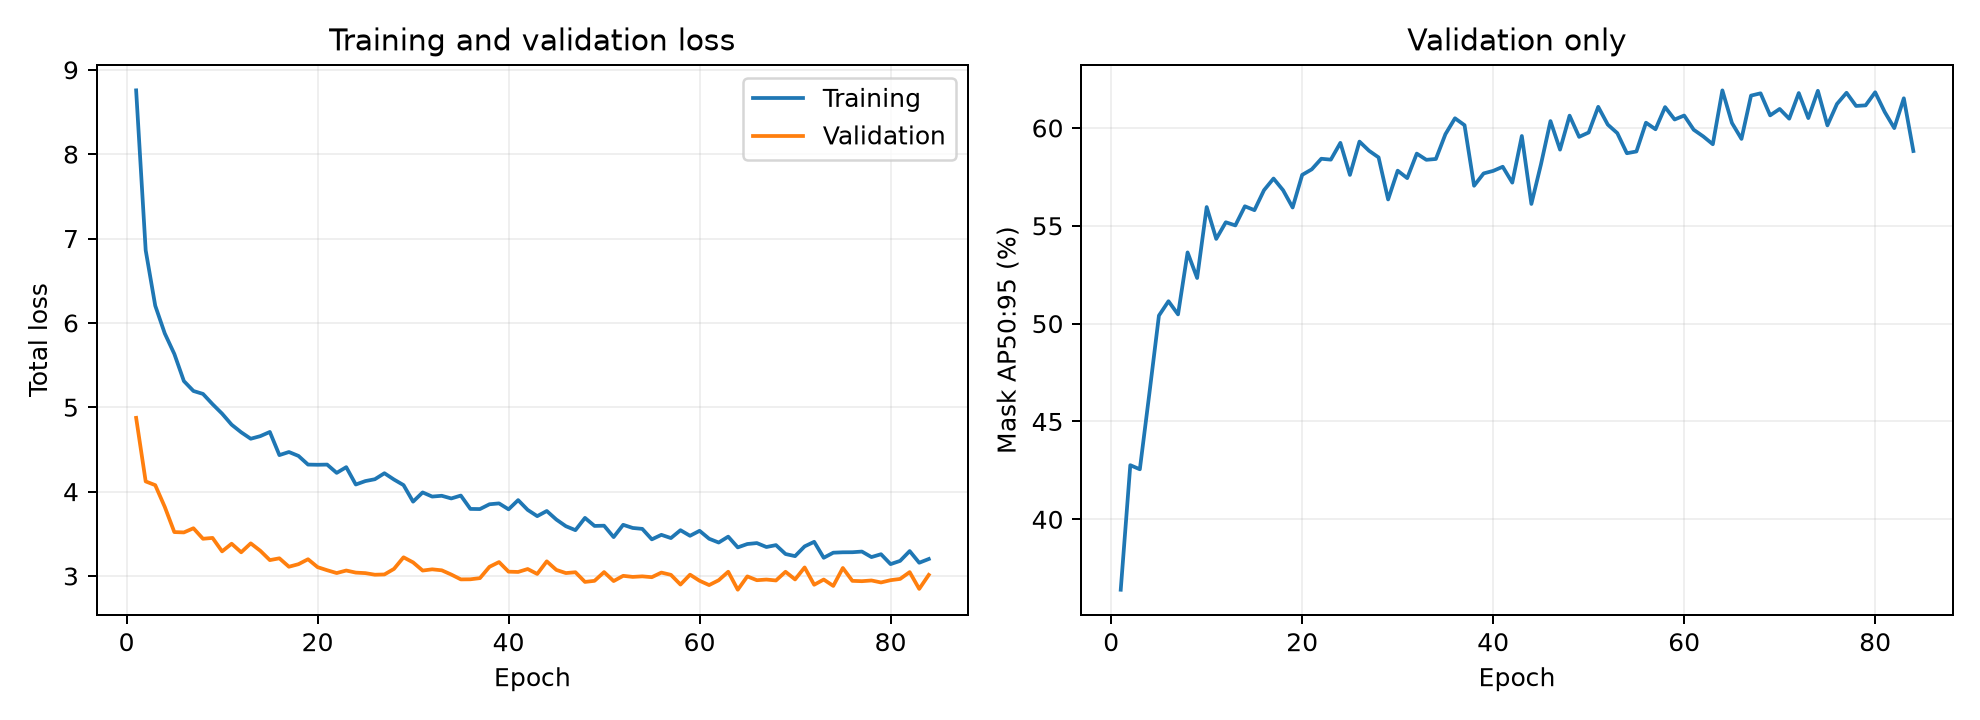

yolo26m_seg


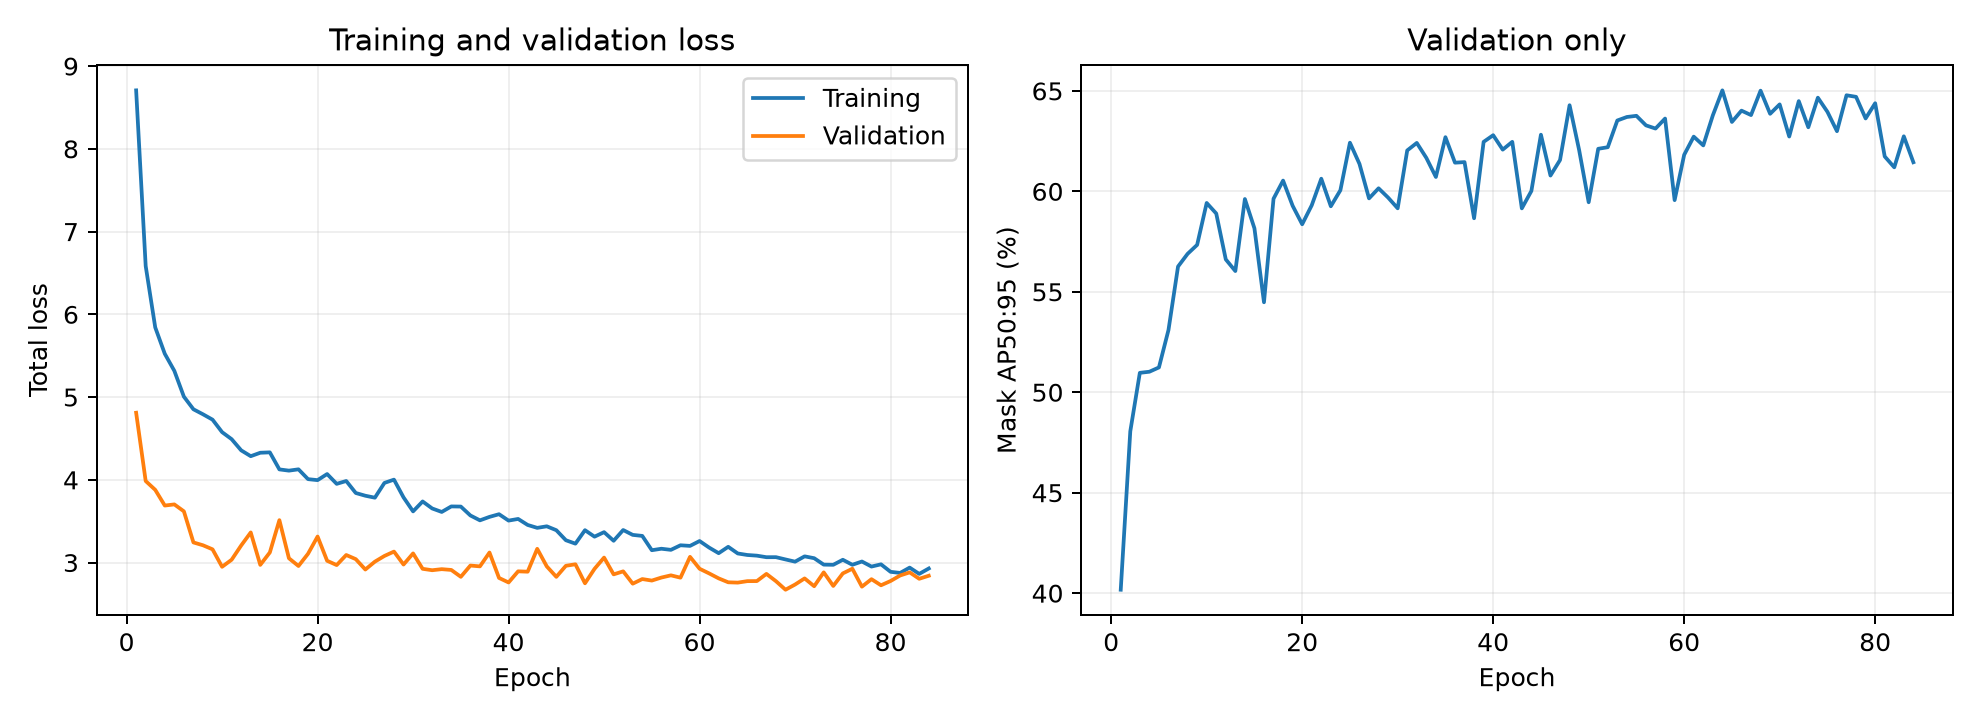

rfdetr_seg


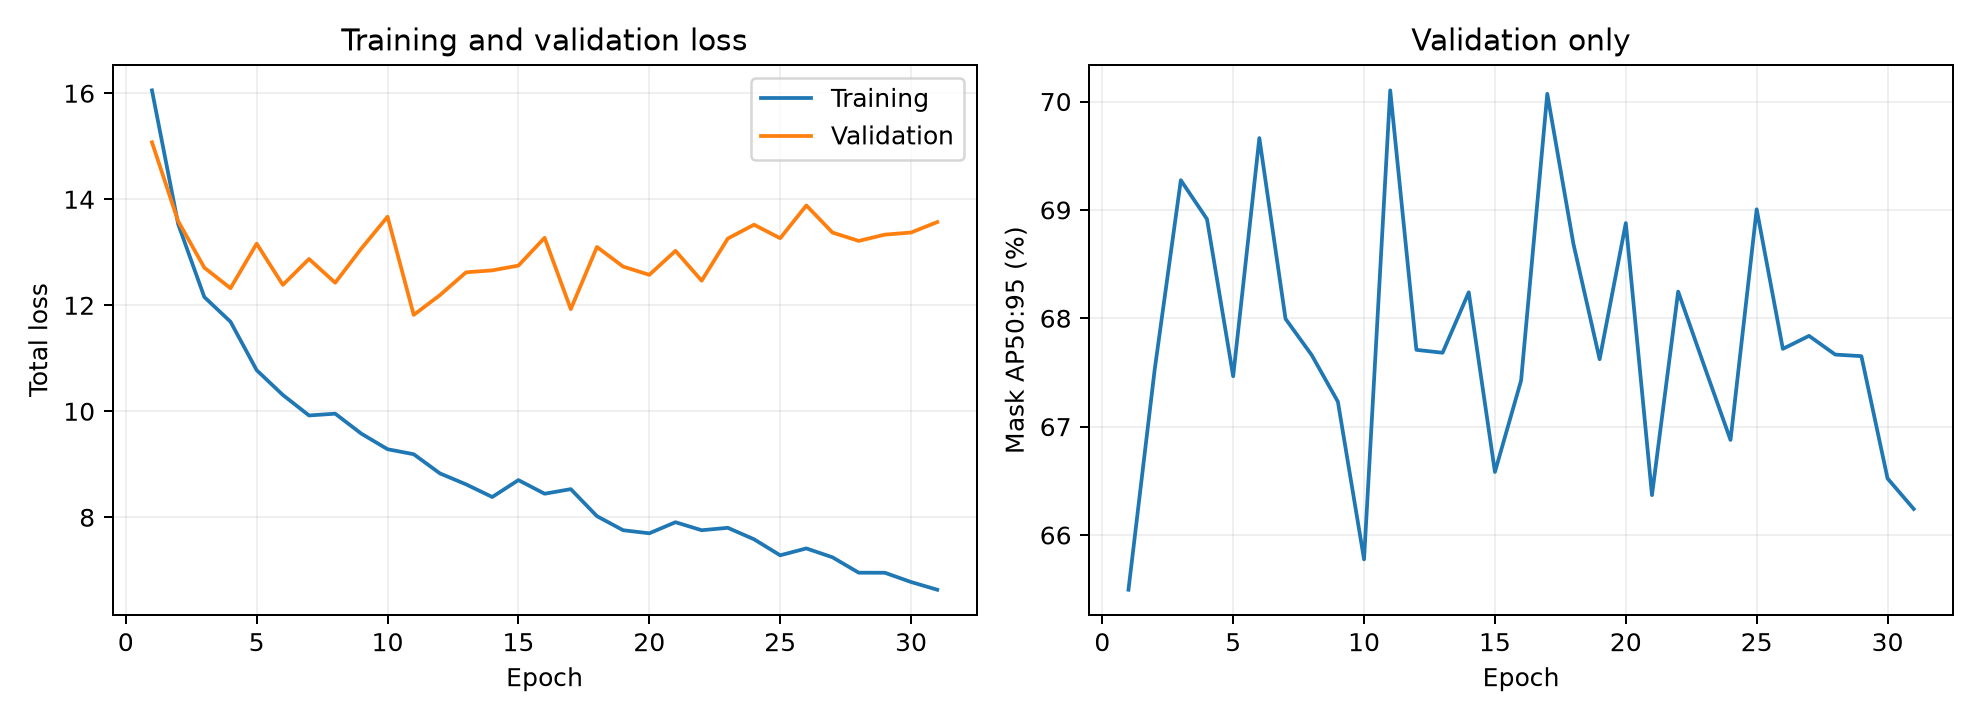

ship_contour


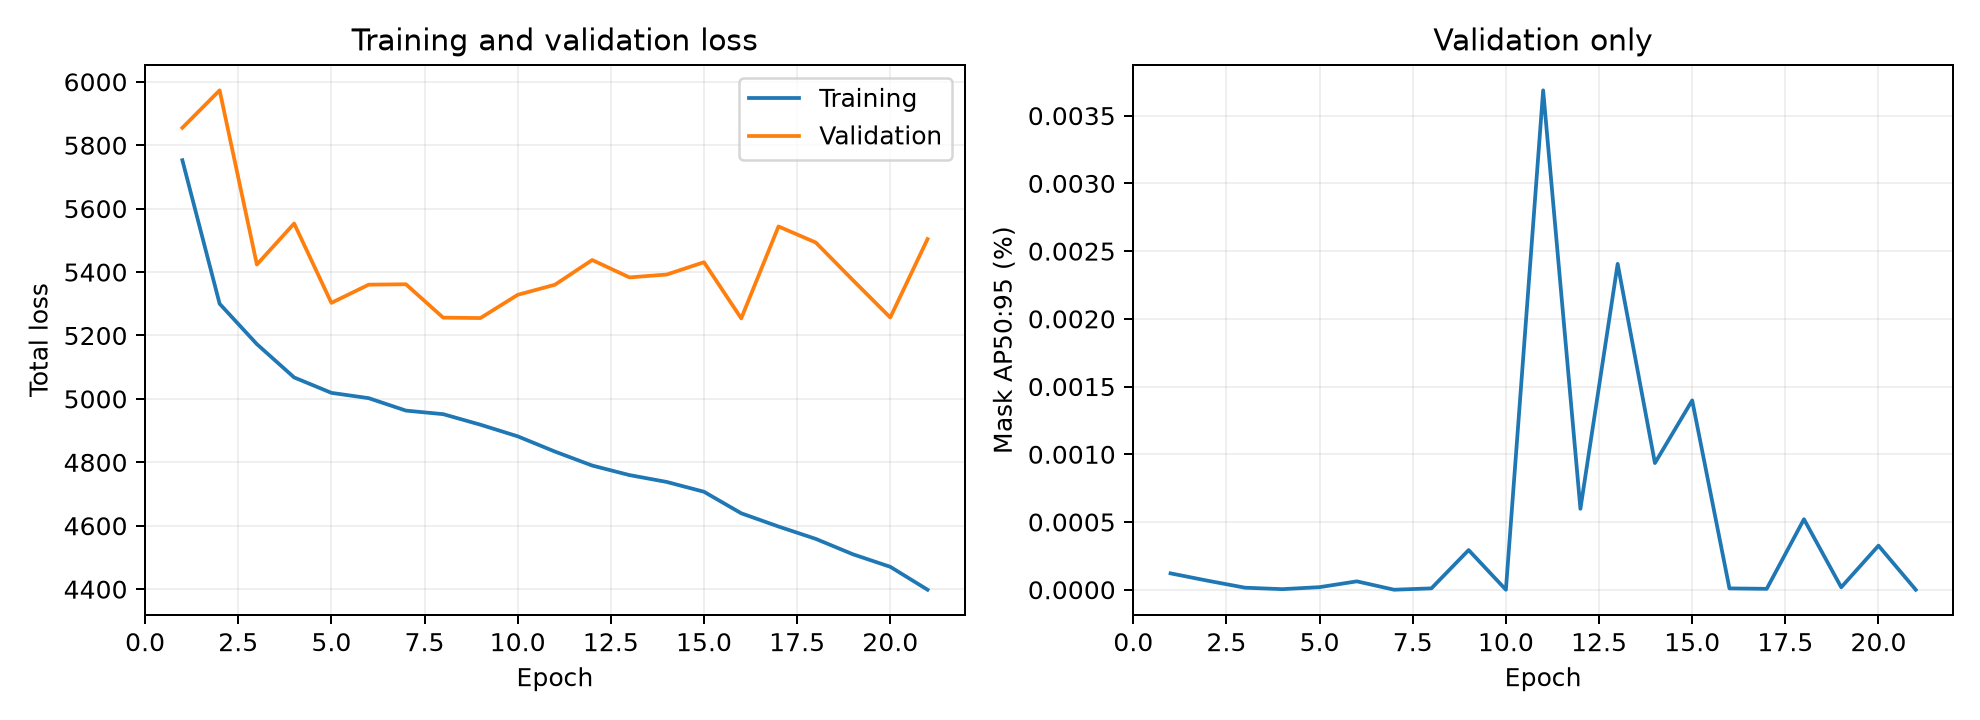

swininsseg


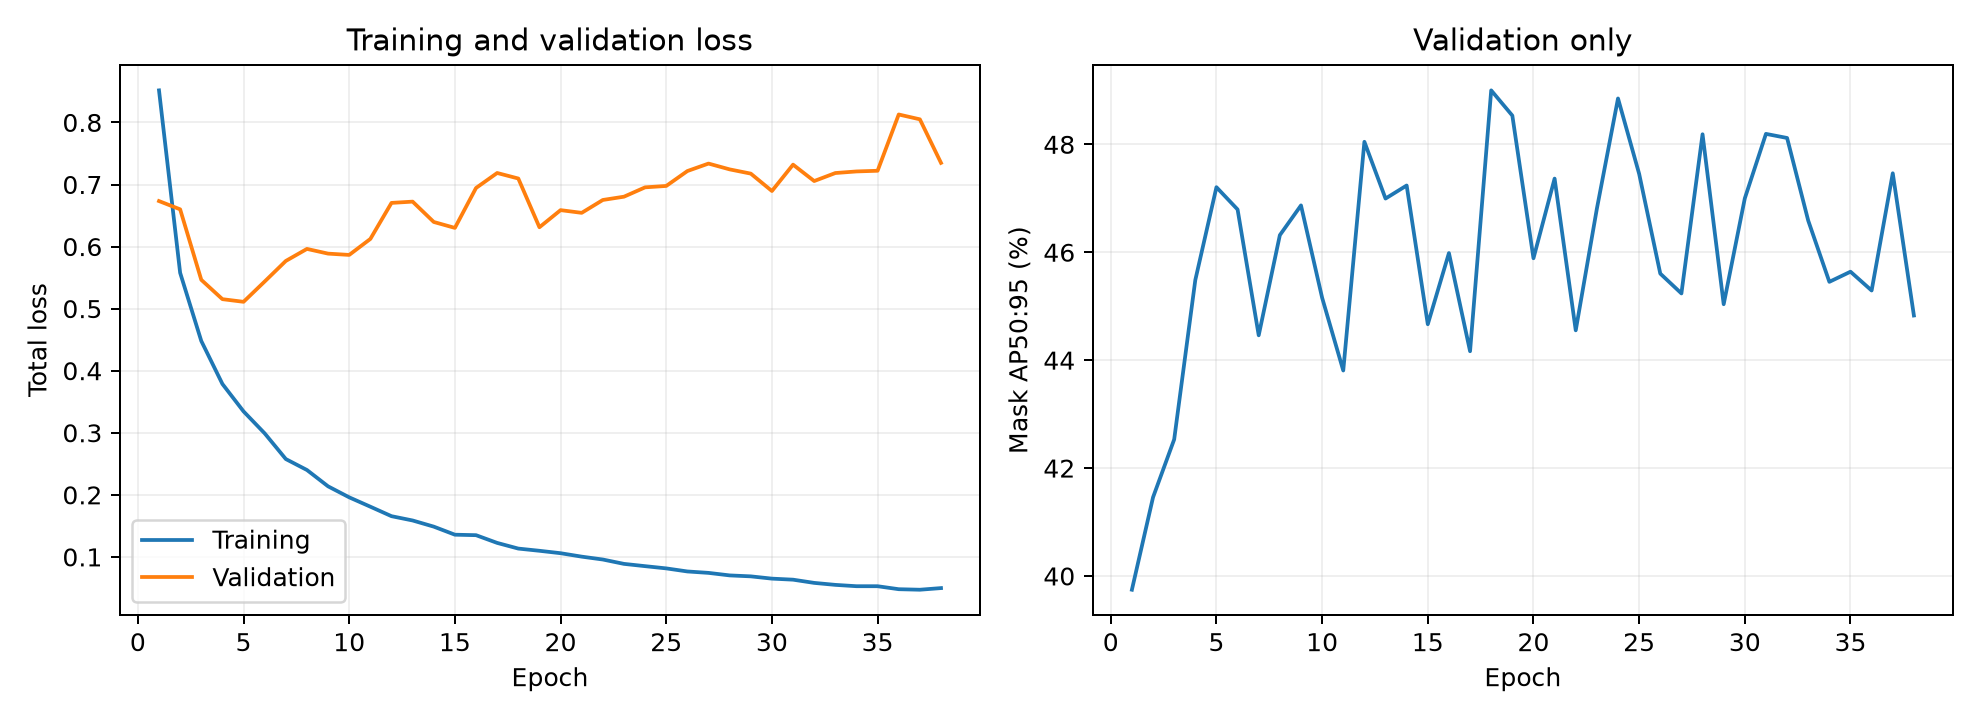

solov2_gala


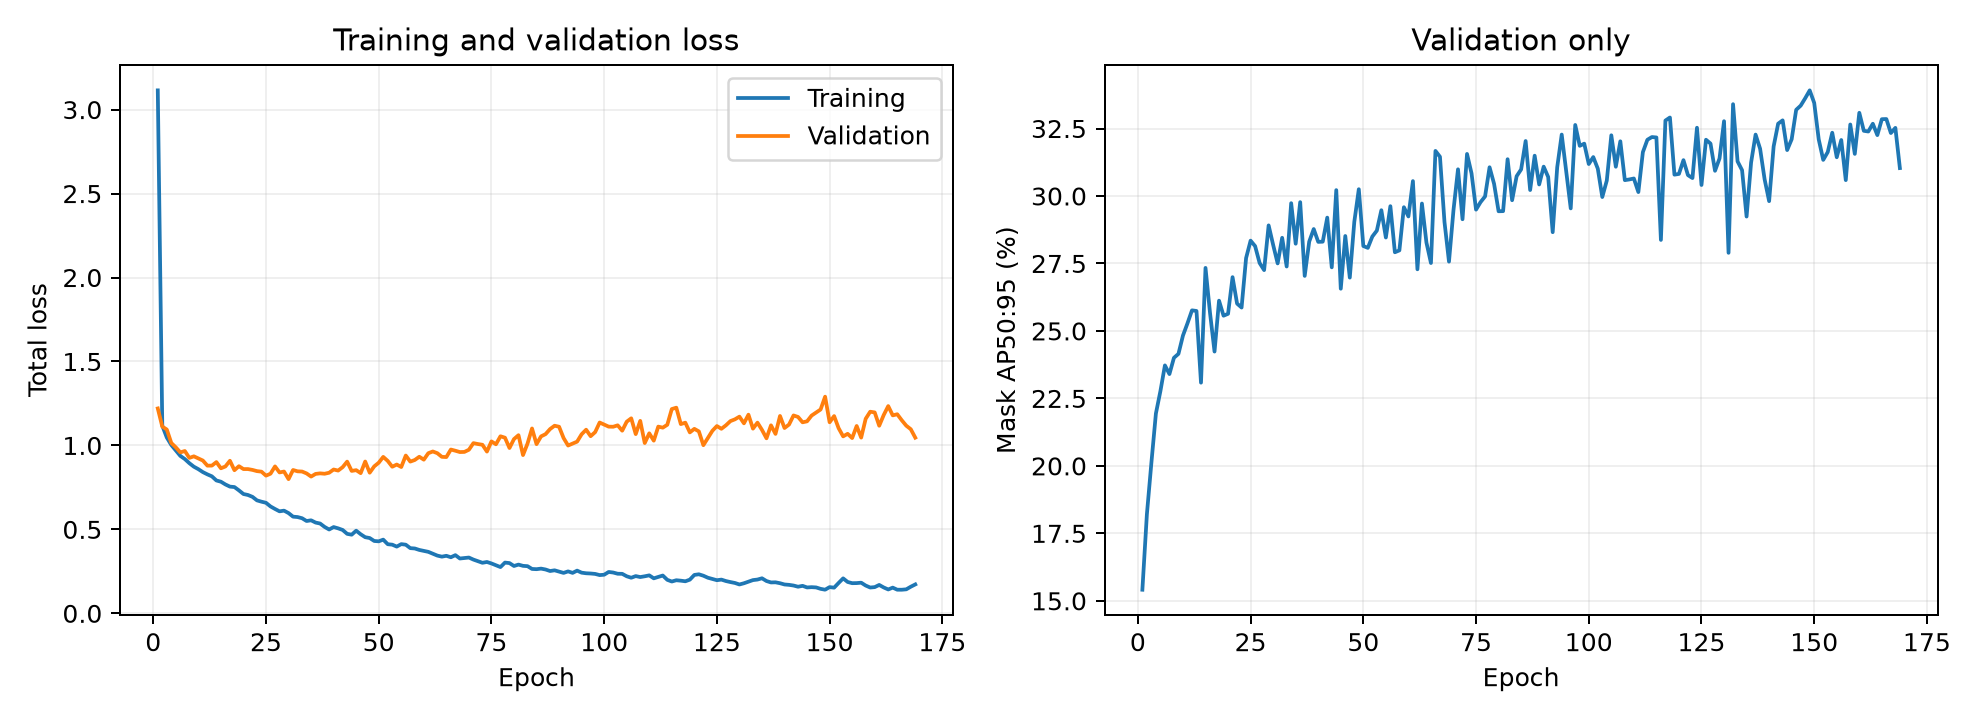

In [3]:
from IPython.display import display, Image
for model in settings['models']:
    path = ROOT / 'runs/visible' / model / settings['experiment'] / 'figures/learning_curves.png'
    if path.is_file():
        print(model)
        display(Image(filename=str(path)))


## Same test image segmented by every completed model


all_models_same_test_image.png


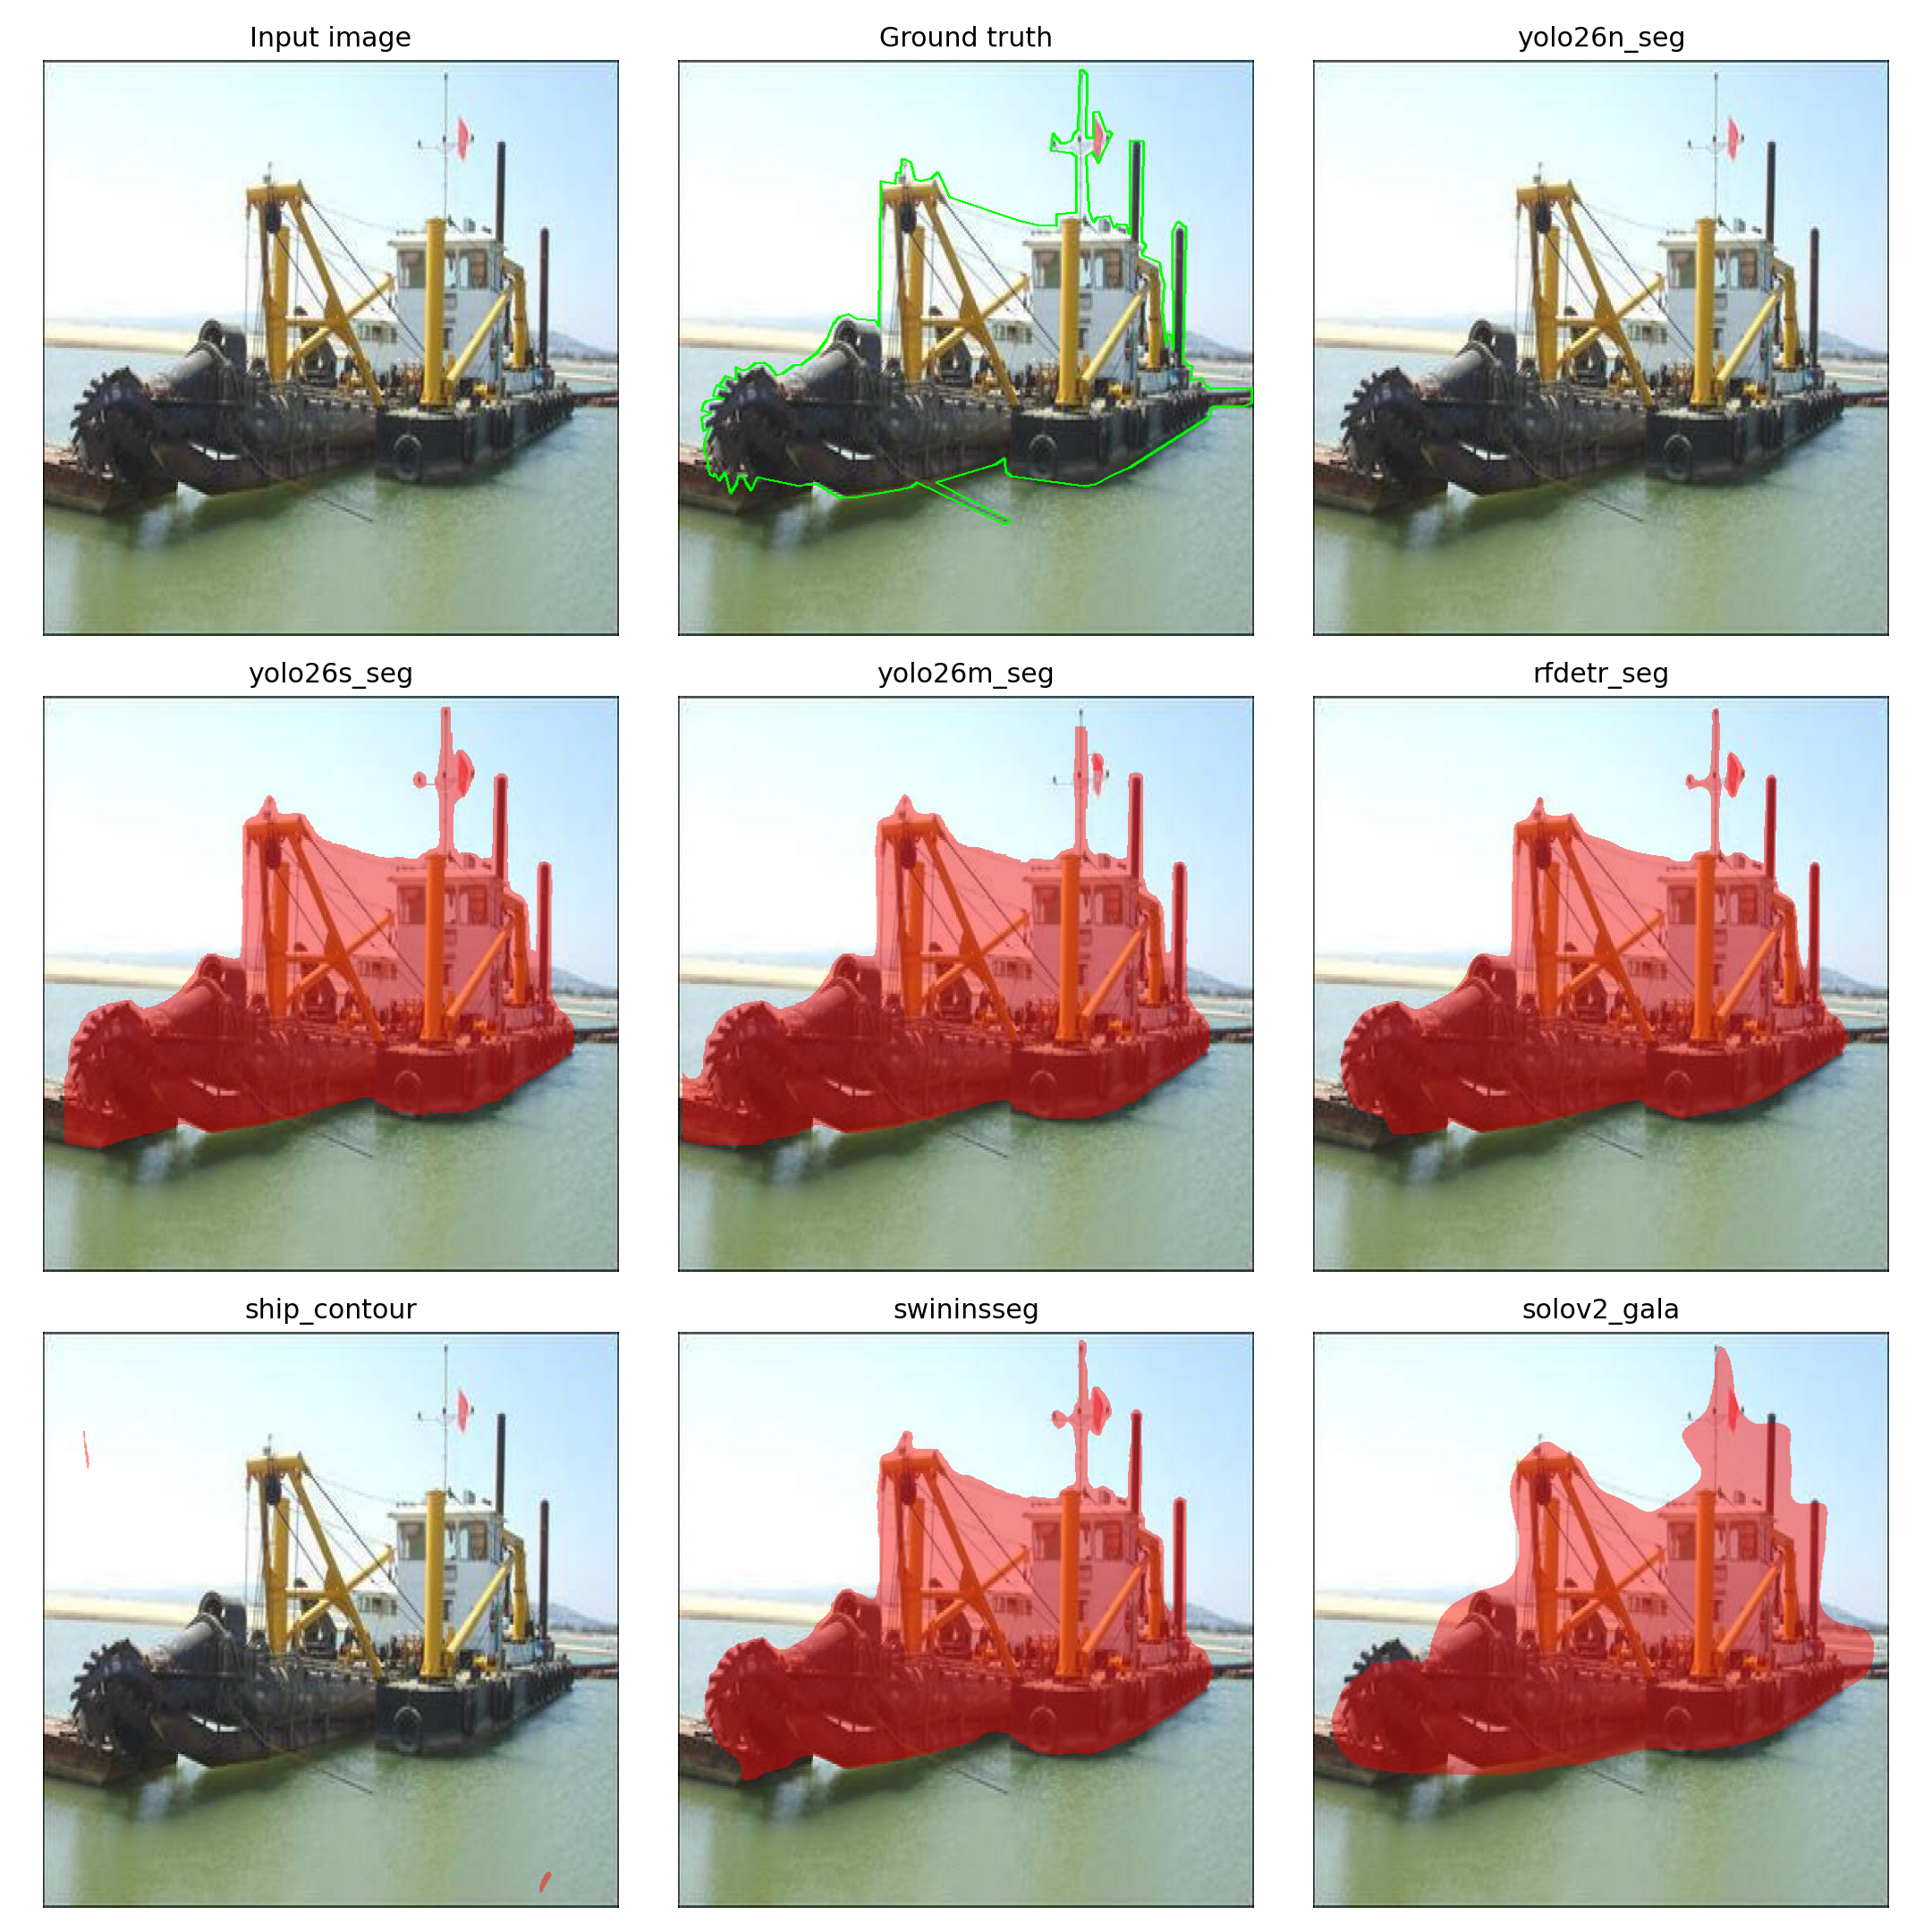

rfdetr_seg.png


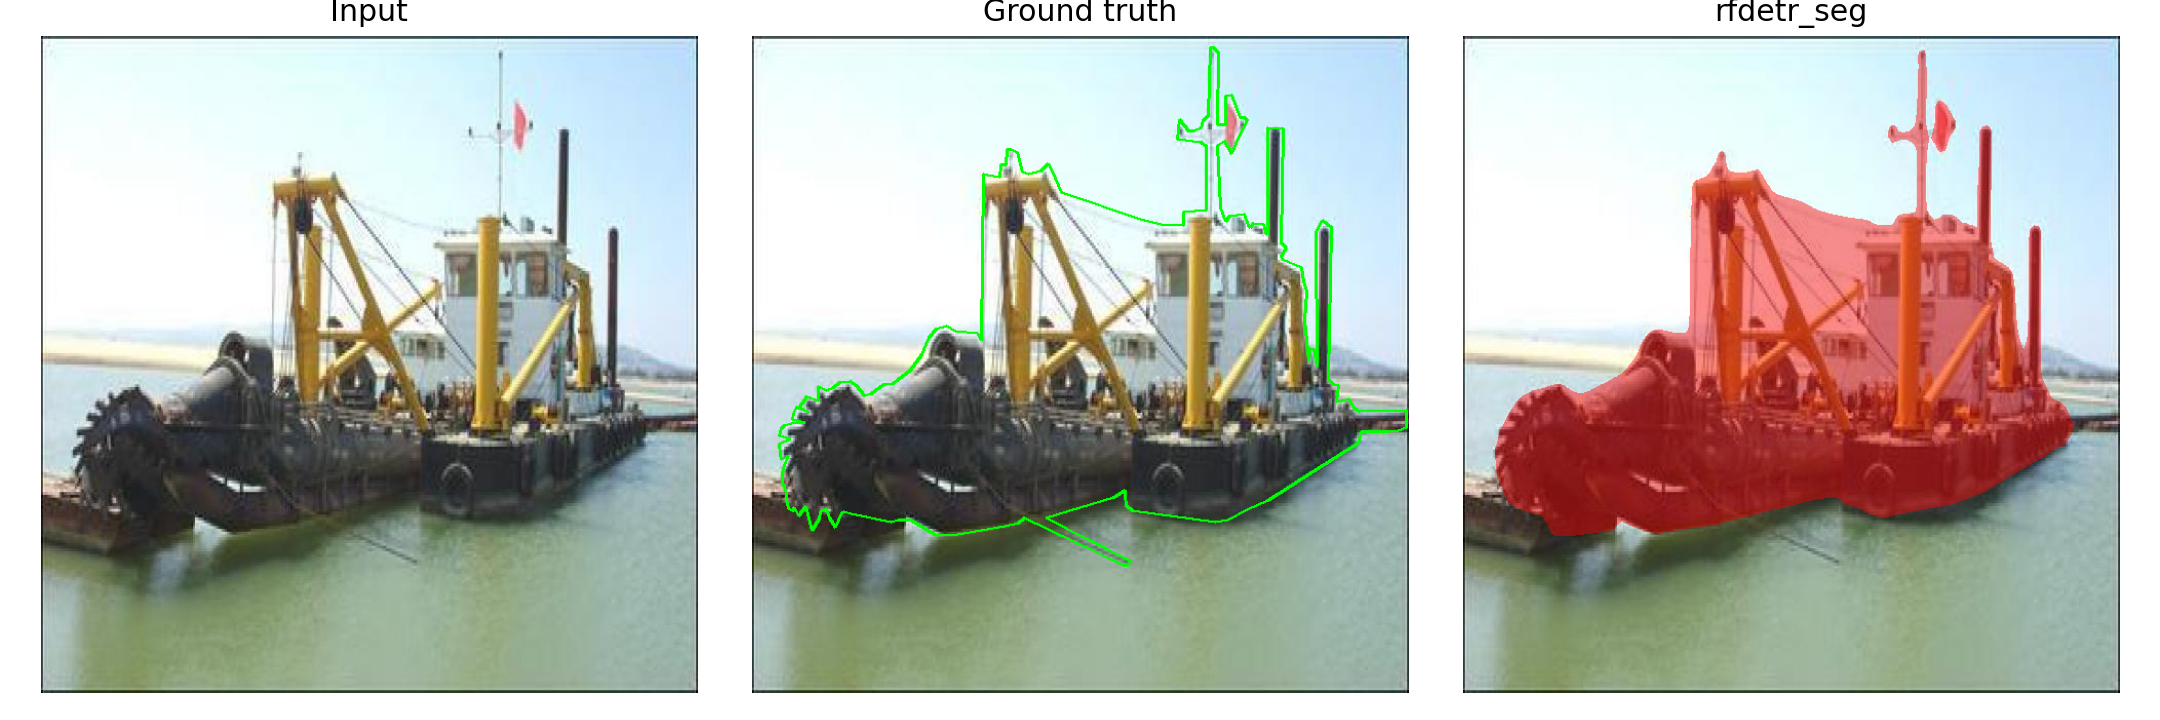

ship_contour.png


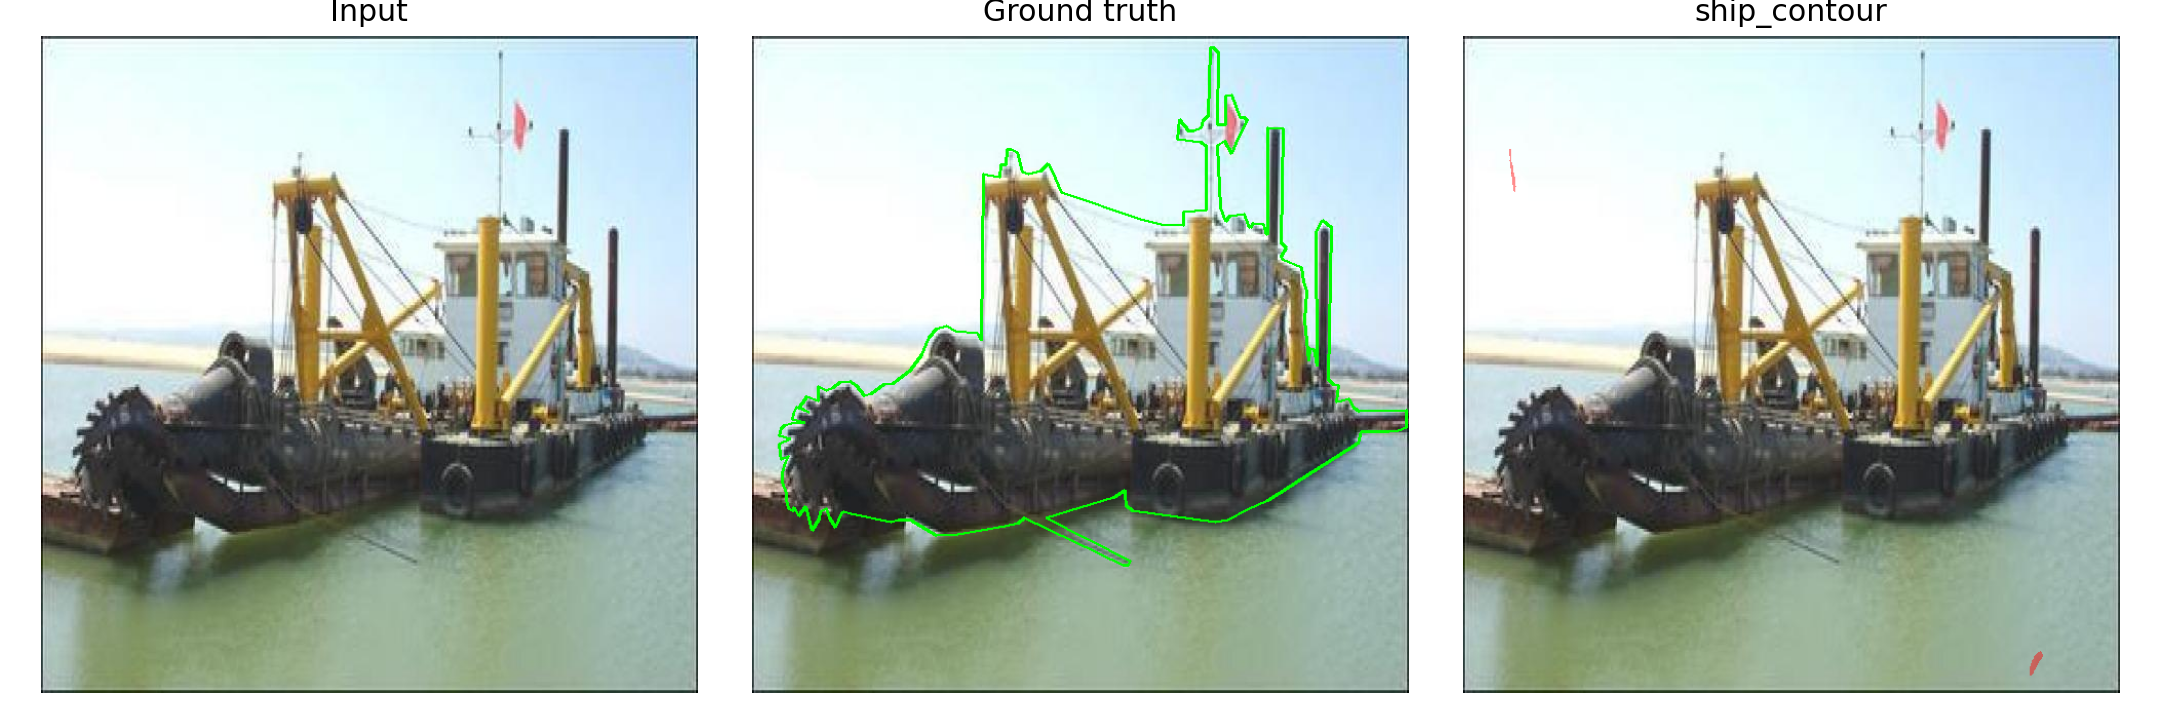

solov2_gala.png


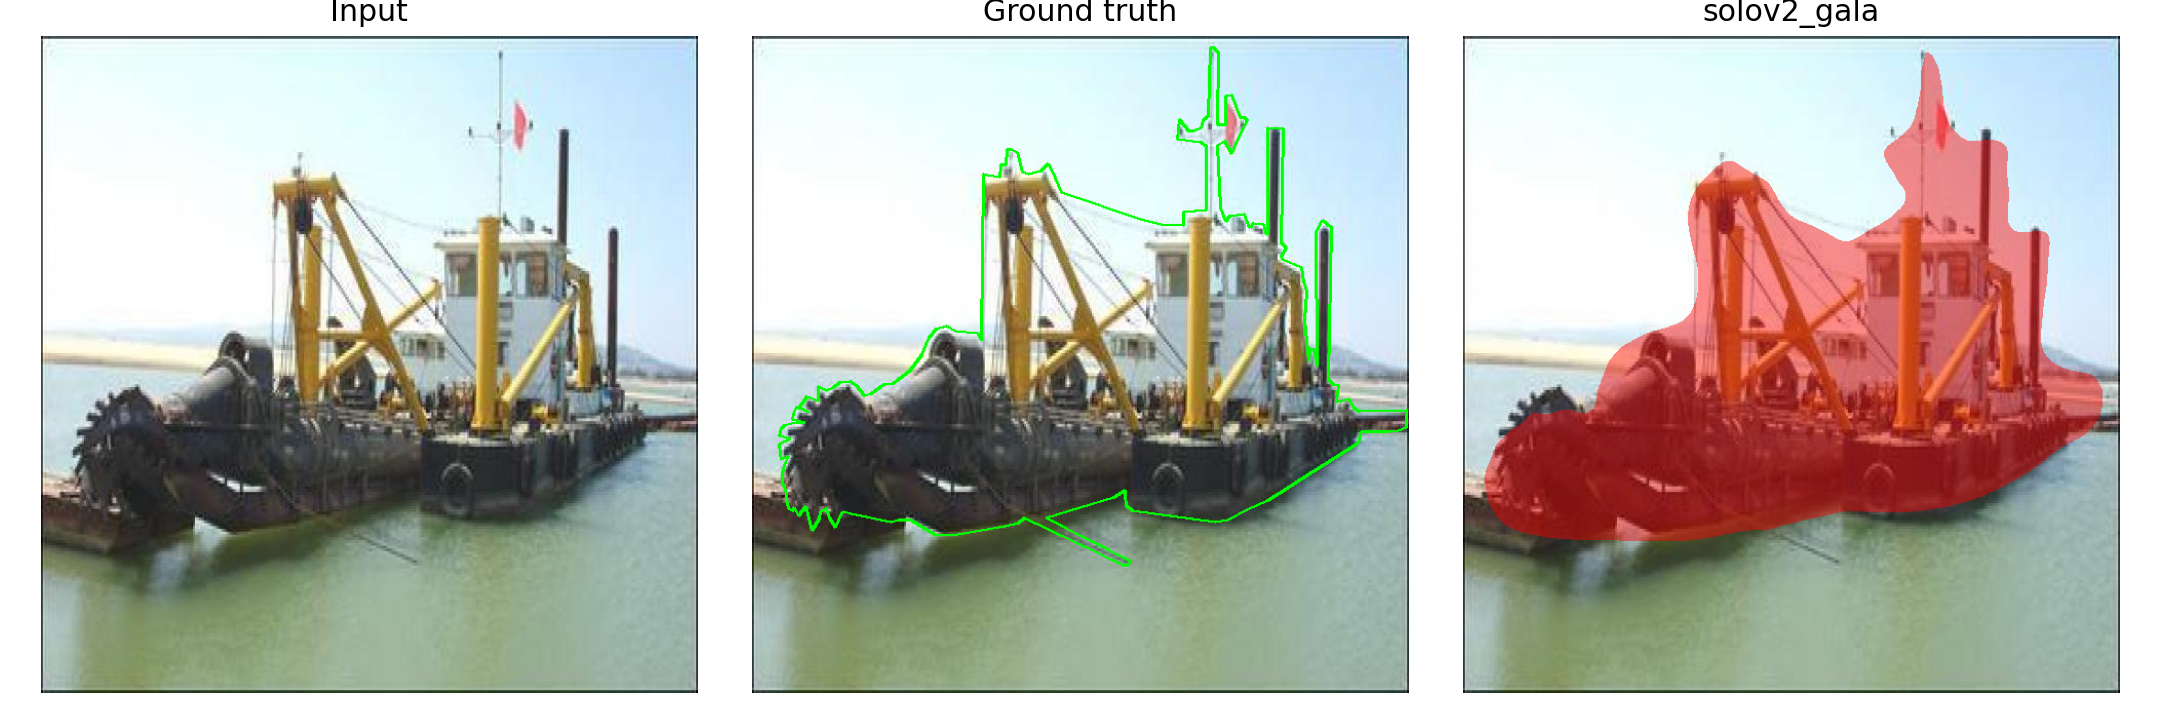

swininsseg.png


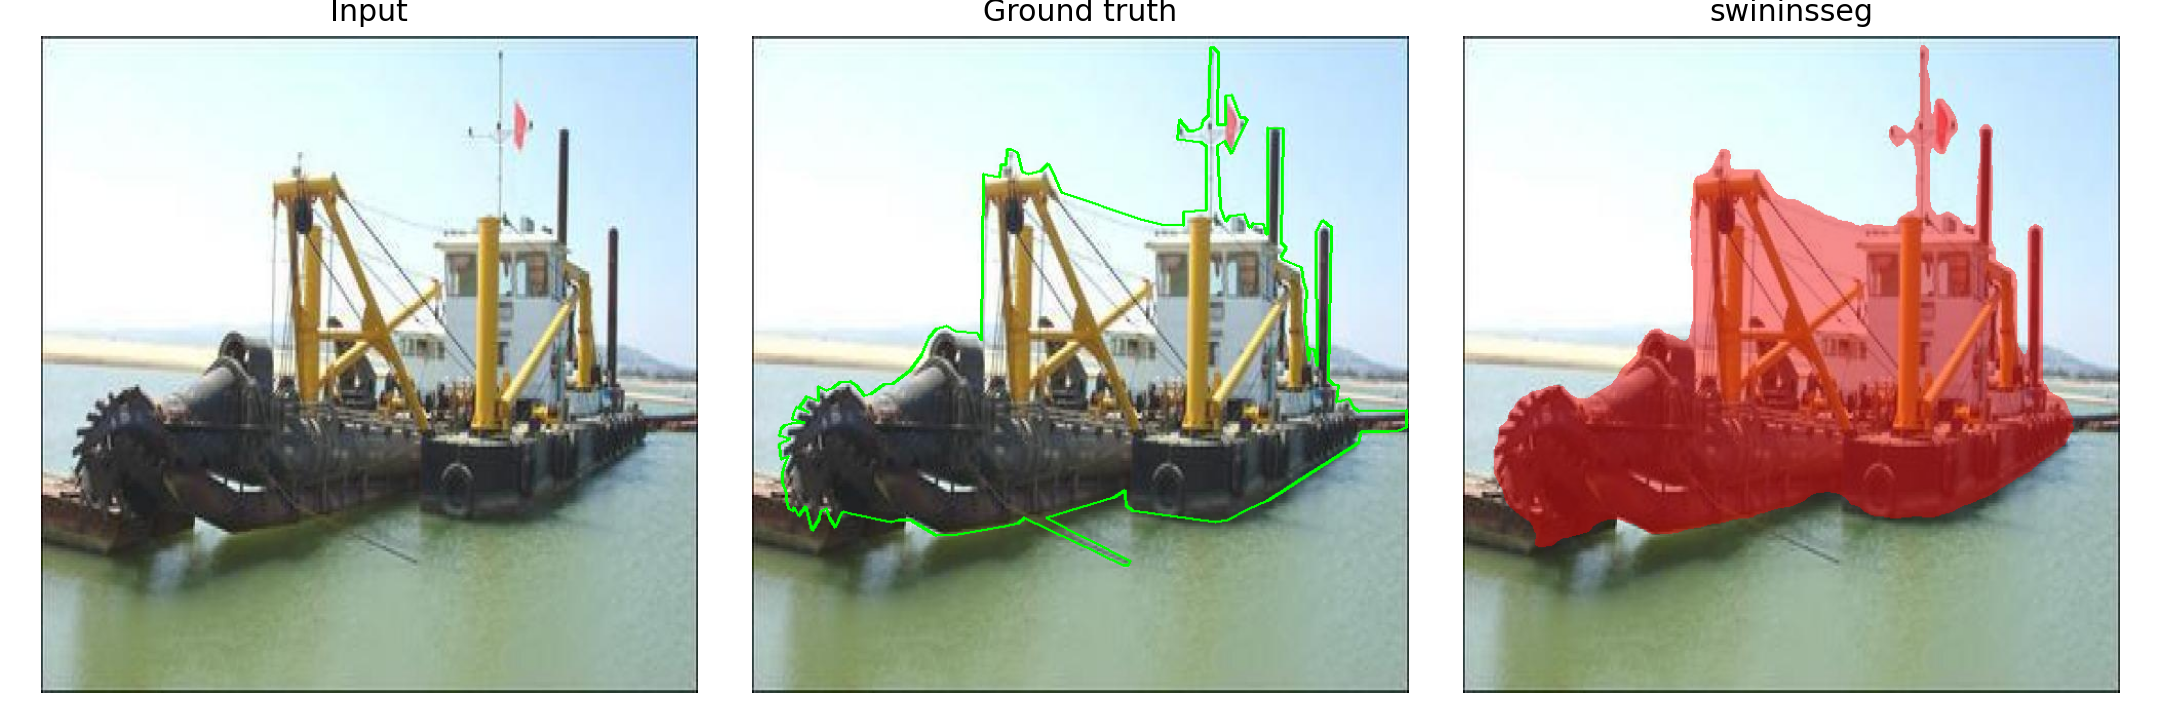

yolo26m_seg.png


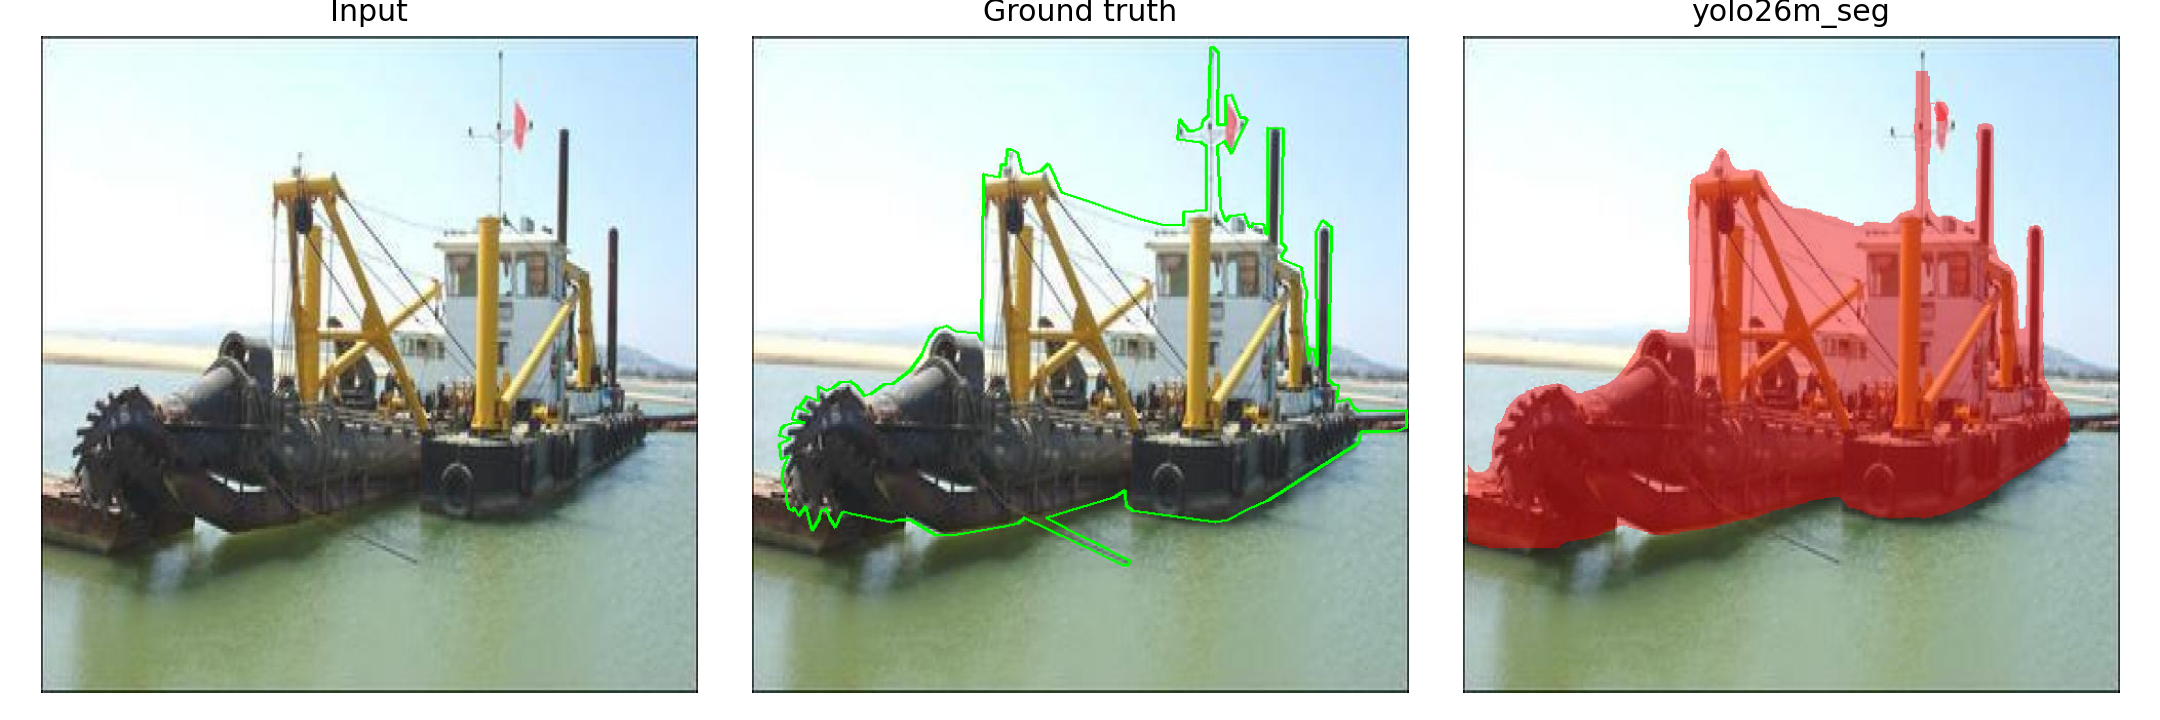

yolo26n_seg.png


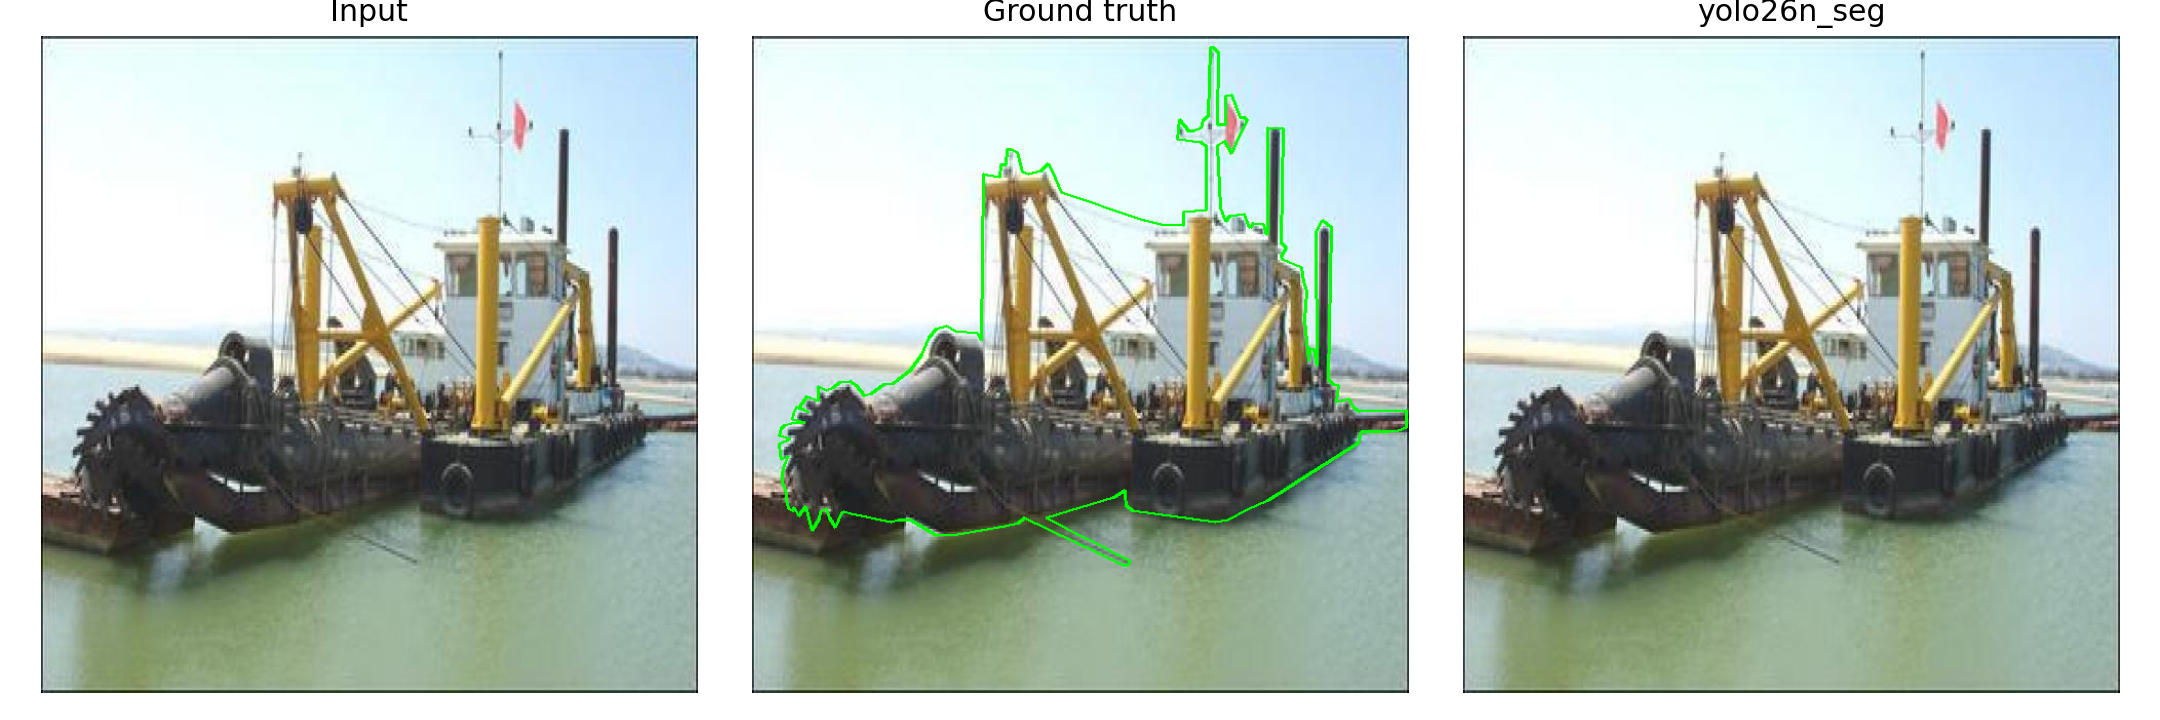

yolo26s_seg.png


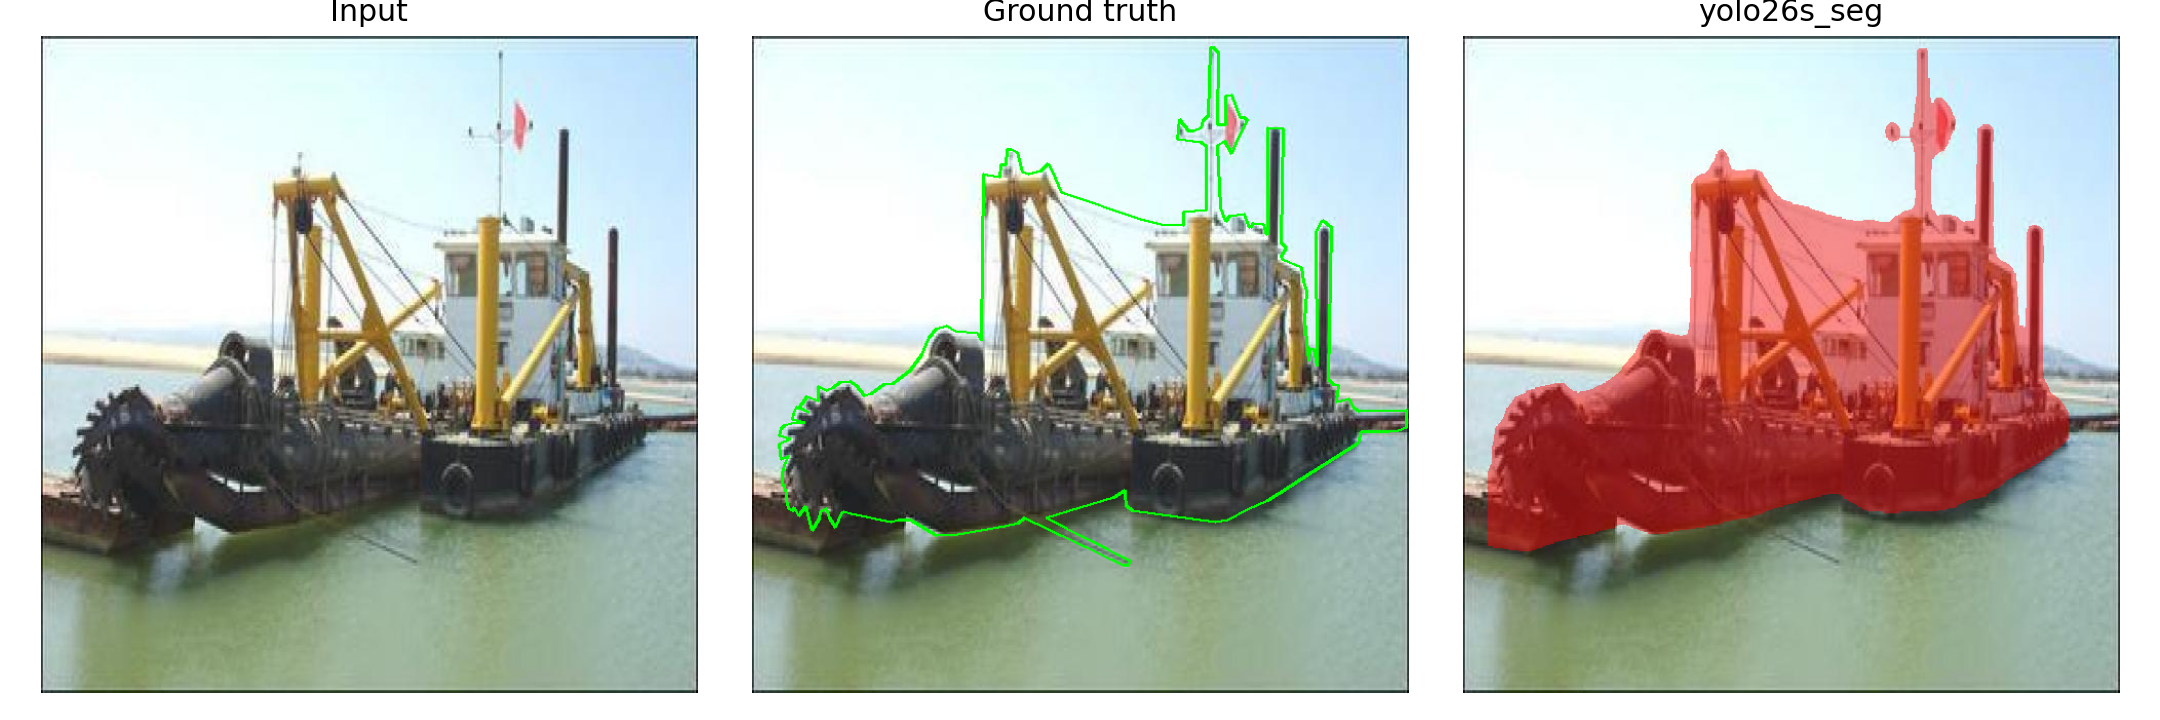

In [4]:
subprocess.run([sys.executable, str(ROOT / 'scripts/visualise_visible.py')], check=True)
for path in sorted((ROOT / 'reports/qualitative').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))
